# CANFAR | SF-only rSFMS for 7000 (SFH16) and 8900

Upload this notebook to `/arc/home/RongjunHuang/ICRAR/further` and select **Run All**
in a Python kernel with NumPy, Pandas, Astropy, SciPy and Matplotlib. The notebook
reads the archived FITS products directly. To try one cube first, set
`PRODUCT_IDS = ("IC3392",)`. Run the first code cell by itself to check kernel
startup and imports. The loader then prints its progress for each cube and run.

For 7000, the stellar surface-density and SFH S/N maps come from
`v3tk_v7.6.8_7000/<GALID>_SFH16`; gas, proxy EW and mask come from
`v3tk_v7.6.8_7000/<GALID>`. For 8900, all five inputs come from
`v3tk_v7.6.8/<GALID>`. The loader prints any exclusions, and the `inventory`
table retains each resolved path.

The comparison uses the same galaxies in both panels, with each run selecting
its own SF spaxels. Differences can therefore reflect changes in either SF
selection or measured surface densities. The Paper II selection requires
inclination < 80 degrees, finite mass and gas bin ID, spatial mask = 0, and
finite SFH `SNR_POSTFIT > 25`. SF then requires finite H II SFR density,
proxy H-alpha EW > 6 A, and positive intrinsic H-alpha dispersion < 45 km/s.
The loader checks that selected spaxels also pass the gas product's Balmer
detection criteria. There is no radial cut.

If both runs have the combined NGC4567/8 cube, both use the same
`NGC4567_8_photometric_segmentation_7000.fits` in the CANFAR notebook folder,
subject to a shape and WCS check for each run. Upload that file alongside the
notebook if needed. Labels 1 and 2 select the individual galaxies and exclude
the mixing region. The comparison treats both combined products as projected
and applies Paper II's component-specific axis-ratio correction to both
densities. Other galaxies use the densities stored in the FITS maps.

In [1]:
print("Python kernel is responding.", flush=True)

import os
import sys
from pathlib import Path
from tempfile import TemporaryDirectory

print(f"Python executable: {sys.executable}", flush=True)

# Keep Matplotlib's font/config cache off the mounted CANFAR home directory.
_mpl_cache = TemporaryDirectory(prefix="mauve-rsfms-mpl-", dir="/tmp")
os.environ["MPLCONFIGDIR"] = _mpl_cache.name

print("Importing NumPy...", flush=True)
import numpy as np

print("Importing Pandas...", flush=True)
import pandas as pd

print("Importing Astropy...", flush=True)
from astropy.io import fits
from astropy.wcs import WCS

print("Importing SciPy...", flush=True)
from scipy.ndimage import gaussian_filter

print("Importing Matplotlib (first import may build the font cache)...", flush=True)
import matplotlib.pyplot as plt
from IPython.display import display

print("Imports complete.", flush=True)

PROJECT_ROOT = Path('/arc/home/RongjunHuang/ICRAR/further')
ARCHIVE_ROOT = Path('/arc/projects/mauve/products')
RUN_ROOTS = {
    '7000 (SFH16)': ARCHIVE_ROOT / 'v3tk_v7.6.8_7000',
    '8900': ARCHIVE_ROOT / 'v3tk_v7.6.8',
}
PRODUCT_IDS = None  # All products in the Paper II geometry table, or e.g. ('IC3392',).
SEGMENTATION = PROJECT_ROOT / 'NGC4567_8_photometric_segmentation_7000.fits'

X_LIMITS, Y_LIMITS = (6.0, 11.0), (-4.0, 1.0)
MAP_GALAXIES = None  # Show up to three largest median paired changes, or specify galaxy IDs.
PAIR_ID = 'NGC4567_8'
PAIR_LABELS = {'NGC4567': 1, 'NGC4568': 2}

Python kernel is responding.
Python executable: /arc/home/RongjunHuang/.conda/envs/ICRAR/bin/python
Importing NumPy...
Importing Pandas...
Importing Astropy...
Importing SciPy...
Importing Matplotlib (first import may build the font cache)...
Imports complete.


In [2]:
# Paper II geometry snapshot from MAUVE_effective_radii.csv (2026-11-18).
# Embedded so the notebook can run without a separate geometry table.
from io import StringIO

geometry = pd.read_csv(StringIO('''
galaxy notebook_product_id inclination_deg intrinsic_axis_ratio_q0
NGC4189 NGC4189 42 0.2
NGC4192 NGC4192 83 0.2
NGC4222 NGC4222 90 0.2
NGC4254 NGC4254 39 0.2
NGC4294 NGC4294 74 0.2
NGC4321 NGC4321 32 0.2
NGC4351 NGC4351 48 0.2
NGC4383 NGC4383 56 0.2
NGC4396 NGC4396 83 0.2
NGC4535 NGC4535 48 0.2
NGC4567 NGC4567_8 49 0.2
NGC4568 NGC4567_8 70 0.2
NGC4298 NGC4298 52 0.2
NGC4302 NGC4302 90 0.2
NGC4330 NGC4330 90 0.2
NGC4388 NGC4388 83 0.2
NGC4402 NGC4402 80 0.2
NGC4424 NGC4424 61 0.2
NGC4501 NGC4501 65 0.2
NGC4522 NGC4522 82 0.2
NGC4654 NGC4654 61 0.2
NGC4694 NGC4694 62 0.2
NGC4064 NGC4064 70 0.2
NGC4216 NGC4216 90 0.2
NGC4293 NGC4293 67 0.2
NGC4380 NGC4380 61 0.2
NGC4394 NGC4394 32 0.2
NGC4405 NGC4405 46 0.2
NGC4419 NGC4419 74 0.2
NGC4450 NGC4450 51 0.2
IC3392 IC3392 68 0.2
NGC4457 NGC4457 37 0.2
NGC4548 NGC4548 37 0.2
NGC4569 NGC4569 69 0.2
NGC4579 NGC4579 40 0.2
NGC4580 NGC4580 46 0.2
NGC4606 NGC4606 69 0.2
NGC4607 NGC4607 90 0.2
NGC4689 NGC4689 38 0.2
NGC4698 NGC4698 66 0.2
'''), sep=r'\s+')


In [3]:
PRODUCT_NAMES = {
    'mass': ('spatial_binning_maps_further', 'SPATIAL_BINNING_maps_further'),
    'sfh': ('sfh_maps',),
    'gas': ('gas_bin_maps_further', 'gas_BIN_maps_further'),
    'ew': ('proxy_EW_maps_further', 'proxy_EW_maps'),
    'mask': ('mask',),
}


def product_paths(run, product_id):
    paths = {}
    for kind, names in PRODUCT_NAMES.items():
        sfh16 = run == '7000 (SFH16)' and kind in ('mass', 'sfh')
        prefix = f'{product_id}_SFH16' if sfh16 else product_id
        folder = RUN_ROOTS[run] / prefix
        candidates = (
            folder / f'{prefix}_{name}.fits{compression}'
            for name in names for compression in ('', '.gz')
        )
        paths[kind] = next((path for path in candidates if path.is_file()), None)
    return paths


def read_maps(path, *names):
    # Disable memmap for FITS with scaled integers as well as float maps.
    with fits.open(path, memmap=False) as hdus:
        return [hdus[name].data for name in names], hdus[names[0]].header.copy()


def check_grid(reference, other, shape, label):
    wcs_a, wcs_b = WCS(reference).celestial, WCS(other).celestial
    if not (wcs_a.has_celestial and wcs_b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x = [0, nx - 1, 0, nx - 1, (nx - 1) / 2]
    y = [0, 0, ny - 1, ny - 1, (ny - 1) / 2]
    separation = wcs_a.pixel_to_world(x, y).separation(wcs_b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(separation).all() or separation.max() > 0.05:
        raise ValueError(f'{label}: WCS disagrees with the mass grid (tolerance 0.05 arcsec)')


def load_components(paths, components):
    (mass,), mass_header = read_maps(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    (ew,), ew_header = read_maps(paths['ew'], 'PROXY_EWHA')
    (snr,), snr_header = read_maps(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=False) as gas:
        gas_header = gas[0].header
        if str(gas_header['BPTMODE']).strip().lower() != 'both':
            raise ValueError('expected BPTMODE=both in the gas FITS file')
        bin_id = gas['BIN_ID'].data
        sfr = gas['LOGSFR_SURFACE_DENSITY_HII'].data
        sigma_obs = gas['HA6562_SIGMA'].data.astype(float)
        sigma_instr = gas['HA6562_SIGMA_CORR'].data.astype(float)
        maps = (ew, snr, bin_id, sfr, sigma_obs, sigma_instr)
        if mass.ndim != 2 or any(array.shape != mass.shape for array in maps):
            raise ValueError('mass, gas, EW and SFH S/N maps must have the same 2D shape')
        check_grid(mass_header, gas['BIN_ID'].header, mass.shape, 'gas')
        check_grid(mass_header, ew_header, mass.shape, 'EW')
        check_grid(mass_header, snr_header, mass.shape, 'SFH S/N')
        with fits.open(paths['mask'], memmap=False) as hdus:
            mask = hdus['MASKFILE'].data['MASK']
            if mask.size != mass.size:
                raise ValueError('spatial mask length differs from the mass map')
            mask = mask.reshape(mass.shape)

        sigma_sq = sigma_obs**2 - sigma_instr**2
        usable = (np.isfinite(mass) & np.isfinite(bin_id) & (mask == 0)
                  & np.isfinite(snr) & (snr > 25))
        sf = (usable & np.isfinite(sfr) & np.isfinite(ew) & (ew > 6)
              & np.isfinite(sigma_sq) & (sigma_sq > 0) & (sigma_sq < 45**2))
        sn_cut, floor = float(gas_header['CUT_SN']), float(gas_header['NOISE'])
        if not (np.isfinite(sn_cut) and np.isfinite(floor) and sn_cut > 0 and floor > 0):
            raise ValueError('invalid CUT_SN or NOISE in the gas FITS file')
        for line in ('HA6562', 'HB4861'):
            flux = gas[f'{line}_FLUX'].data[sf].astype(float)
            error = gas[f'{line}_FLUX_ERR'].data[sf].astype(float)
            with np.errstate(divide='ignore', invalid='ignore'):
                detected = (np.isfinite(flux) & np.isfinite(error) & (error > 0)
                            & (flux >= floor) & (flux / error >= sn_cut))
            if not detected.all():
                raise ValueError(f'{line}: SF selection overlaps Balmer non-detections')

    is_pair = components.iloc[0].notebook_product_id == PAIR_ID
    if is_pair:
        (labels,), header = read_maps(SEGMENTATION, 0)
        if labels.shape != mass.shape:
            raise ValueError('NGC4567/8 segmentation shape differs from the mass map')
        check_grid(mass_header, header, mass.shape, 'NGC4567/8 segmentation')
        if not np.all(np.isnan(labels) | np.isin(labels, (0, *PAIR_LABELS.values()))):
            raise ValueError('unexpected NGC4567/8 segmentation labels')

    samples, sf_pixels = {}, {}
    for row in components.itertuples(index=False):
        if is_pair:
            selected = sf & (labels == PAIR_LABELS[row.galaxy])
            q0 = row.intrinsic_axis_ratio_q0
            cos_i = np.cos(np.deg2rad(row.inclination_deg))
            offset = np.log10(np.sqrt((1 - q0**2) * cos_i**2 + q0**2))
        else:
            selected, offset = sf, 0.0
        samples[row.galaxy] = (mass[selected].astype(float) + offset,
                               sfr[selected].astype(float) + offset)
        sf_pixels[row.galaxy] = np.flatnonzero(selected).astype(np.int32)
    return samples, sf_pixels, mass.shape, mass_header


In [4]:
for run, root in RUN_ROOTS.items():
    print(f"Checking {run} archive root: {root}", flush=True)
    if not root.is_dir():
        raise FileNotFoundError(f'{run} archive root is unavailable: {root}')

catalogue_ids = set(geometry.notebook_product_id)
requested_ids = catalogue_ids if PRODUCT_IDS is None else set(PRODUCT_IDS)
if not requested_ids or requested_ids - catalogue_ids:
    raise ValueError(f'PRODUCT_IDS must select known cube IDs. Unknown: {requested_ids - catalogue_ids}')

inventory_rows, count_rows = [], []
matched = {run: {} for run in RUN_ROOTS}
paired, pairing_rows = {}, []
new_run, old_run = RUN_ROOTS
for product_id in sorted(requested_ids):
    components = geometry.loc[geometry.notebook_product_id.eq(product_id)]
    eligible = components.loc[np.isfinite(components.inclination_deg)
                              & components.inclination_deg.lt(80)]
    samples_by_run, grids_by_run = {}, {}
    for run in RUN_ROOTS:
        print(f"{product_id} | {run}: checking input paths", flush=True)
        paths = product_paths(run, product_id)
        missing = [kind for kind, path in paths.items() if path is None]
        if eligible.empty:
            status = 'excluded by inclination'
        elif missing:
            status = 'missing ' + ', '.join(missing)
        elif product_id == PAIR_ID and not SEGMENTATION.is_file():
            status = f'missing {SEGMENTATION.name}'
        else:
            try:
                print(f"{product_id} | {run}: reading FITS and selecting SF", flush=True)
                samples, pixels, shape, header = load_components(paths, eligible)
                samples_by_run[run] = samples
                grids_by_run[run] = (pixels, shape, header)
                status = 'loaded'
            except (KeyError, OSError, ValueError) as exc:
                status = f'{type(exc).__name__}: {exc}'
        print(f"{product_id} | {run}: {status}", flush=True)
        inventory_rows.append(dict(run=run, product_id=product_id, status=status, **paths))

    if len(samples_by_run) == len(RUN_ROOTS):
        new_pixels, new_shape, new_header = grids_by_run[new_run]
        old_pixels, old_shape, old_header = grids_by_run[old_run]
        try:
            if new_shape != old_shape:
                raise ValueError(f'cross-run shape mismatch: {new_shape} versus {old_shape}')
            check_grid(old_header, new_header, old_shape, f'{product_id} cross-run')
            pairing_status = 'paired on native grid'
        except ValueError as exc:
            pairing_status = str(exc)
        pairing_rows.append(dict(product_id=product_id, status=pairing_status))
        if pairing_status == 'paired on native grid':
            for name, (x0, y0) in samples_by_run[old_run].items():
                x1, y1 = samples_by_run[new_run][name]
                pixel, i0, i1 = np.intersect1d(old_pixels[name], new_pixels[name],
                                               assume_unique=True, return_indices=True)
                paired[name] = dict(
                    product_id=product_id, shape=old_shape, header=old_header, pixel=pixel,
                    old_pixels=old_pixels[name], new_pixels=new_pixels[name],
                    x0=x0[i0], y0=y0[i0], x1=x1[i1], y1=y1[i1],
                )
        for run, samples in samples_by_run.items():
            matched[run].update(samples)
            for name, (x, y) in samples.items():
                in_view = ((x >= X_LIMITS[0]) & (x <= X_LIMITS[1])
                           & (y >= Y_LIMITS[0]) & (y <= Y_LIMITS[1]))
                count_rows.append(dict(galaxy=name, product_id=product_id, run=run,
                                       SF_total=x.size, SF_in_view=int(in_view.sum())))

inventory = pd.DataFrame(inventory_rows)
display(inventory.pivot(index='product_id', columns='run', values='status'))
if not count_rows:
    raise RuntimeError('No galaxies have readable inputs for both runs. See the inventory above.')

counts = pd.DataFrame(count_rows)
counts['SF_outside_view'] = counts.SF_total - counts.SF_in_view
display(counts.pivot(index='galaxy', columns='run',
                     values=['SF_total', 'SF_in_view', 'SF_outside_view']))
display(counts.groupby('run')[['SF_total', 'SF_in_view', 'SF_outside_view']].sum())
if (counts.groupby('run').SF_in_view.sum() == 0).any():
    raise RuntimeError('At least one run has no SF spaxels in the display window.')

Checking 7000 (SFH16) archive root: /arc/projects/mauve/products/v3tk_v7.6.8_7000
Checking 8900 archive root: /arc/projects/mauve/products/v3tk_v7.6.8
IC3392 | 7000 (SFH16): checking input paths
IC3392 | 7000 (SFH16): reading FITS and selecting SF
IC3392 | 7000 (SFH16): loaded
IC3392 | 8900: checking input paths
IC3392 | 8900: reading FITS and selecting SF
IC3392 | 8900: loaded
NGC4064 | 7000 (SFH16): checking input paths
NGC4064 | 7000 (SFH16): reading FITS and selecting SF
NGC4064 | 7000 (SFH16): loaded
NGC4064 | 8900: checking input paths
NGC4064 | 8900: reading FITS and selecting SF
NGC4064 | 8900: loaded
NGC4189 | 7000 (SFH16): checking input paths
NGC4189 | 7000 (SFH16): reading FITS and selecting SF
NGC4189 | 7000 (SFH16): loaded
NGC4189 | 8900: checking input paths
NGC4189 | 8900: reading FITS and selecting SF
NGC4189 | 8900: loaded
NGC4192 | 7000 (SFH16): checking input paths
NGC4192 | 7000 (SFH16): excluded by inclination
NGC4192 | 8900: checking input paths
NGC4192 | 8900: e

run,7000 (SFH16),8900
product_id,,
IC3392,loaded,loaded
NGC4064,loaded,loaded
NGC4189,loaded,loaded
NGC4192,excluded by inclination,excluded by inclination
NGC4216,excluded by inclination,excluded by inclination
NGC4222,excluded by inclination,excluded by inclination
NGC4254,loaded,loaded
NGC4293,loaded,loaded
NGC4294,loaded,loaded


SF_total           SF_in_view         SF_outside_view     
run     7000 (SFH16)    8900 7000 (SFH16)    8900    7000 (SFH16) 8900
galaxy                                                                
IC3392         13908   13888        13908   13888               0    0
NGC4064         3274    3273         3274    3273               0    0
NGC4189        88582   80671        88582   80671               0    0
NGC4254       453580  466023       453580  466023               0    0
NGC4293          471     471          471     471               0    0
NGC4294        66537   67512        66537   67512               0    0
NGC4298       140421  138402       140421  138402               0    0
NGC4321       382821  375304       382821  375304               0    0
NGC4351        29767   29731        29767   29731               0    0
NGC4380        61763   56075        61763   56075               0    0
NGC4383        15627   14521        15627   14521               0    0
NGC4394        31416   30430        31416   30430               0    0
NGC4405        13486   13569        13486   13569               0    0
NGC4419         5542    5763         5542    5763               0    0
NGC4424         8627    8994         8627    8994               0    0
NGC4450        16656   17186        16656   17186               0    0
NGC4457         5601    5604         5601    5604               0    0
NGC4501       252942  251607       252942  251607               0    0
NGC4535       161648  166914       161648  166914               0    0
NGC4548       103611   99560       103611   99560               0    0
NGC4567        87590   87646        87590   87646               0    0
NGC4568       114364  113474       114364  113474               0    0
NGC4569        44937   45456        44937   45456               0    0
NGC4579       111718  113933       111718  113933               0    0
NGC4580        22173   22425        22173   22425               0    0
NGC4606         1695    1752         1695    1752               0    0
NGC4654       325678  320781       325678  320781               0    0
NGC4689       179946  178326       179946  178326               0    0
NGC4694         1022    1058         1022    1058               0    0
NGC4698         6512    6535         6512    6535               0    0

,SF_total,SF_in_view,SF_outside_view
run,,,
7000 (SFH16),2751915,2751915,0
8900,2736884,2736884,0


## Side-by-side rSFMS

Both versions show the same x and y window as Paper II Figure 1. Each marginal
histogram shows the fraction per bin of SF spaxels inside that joint window
in the corresponding run. Solid lines mark the median and dashed lines mark
the arithmetic mean of the log values. The plots pool spaxels for the scatter, histograms
and contours. The dashed fit uses all selected SF spaxels, including any
outside the displayed window, with equal total weight for each galaxy
that contributes SF spaxels.

The contour version uses a shared 60 x 60 grid smoothed with a Gaussian
of one bin. From the innermost outward, the contours enclose approximately
50%, 80% and 95% of each run's smoothed in-window distribution.

In [5]:
X_LABEL = r'$\log_{10}\,\Sigma_\star\;[\mathrm{M}_\odot\,\mathrm{kpc}^{-2}]$'
Y_LABEL = r'$\log_{10}\,\Sigma_{\rm SFR}\;[\mathrm{M}_\odot\,\mathrm{yr}^{-1}\,\mathrm{kpc}^{-2}]$'
HIST_X = np.linspace(*X_LIMITS, 41)
HIST_Y = np.linspace(*Y_LIMITS, 41)
COLORS = ('#16677d', '#a64f2d')

plot_data, fit_rows, marginal_rows = {}, [], []
for run, samples in matched.items():
    populated = [(x, y) for x, y in samples.values() if x.size]
    x = np.concatenate([x for x, _ in populated])
    y = np.concatenate([y for _, y in populated])
    weights = np.concatenate([np.full(xx.size, 1.0 / xx.size) for xx, _ in populated])
    design = np.column_stack((x, np.ones(x.size)))
    coeff, _, rank, _ = np.linalg.lstsq(design * np.sqrt(weights[:, None]),
                                        y * np.sqrt(weights), rcond=None)
    slope, intercept = coeff if rank == 2 else (np.nan, np.nan)

    in_view = (
        (x >= X_LIMITS[0]) & (x <= X_LIMITS[1]) &
        (y >= Y_LIMITS[0]) & (y <= Y_LIMITS[1])
    )
    for axis, values in (('log stellar density', x[in_view]), ('log SFR density', y[in_view])):
        p16, median, p84 = np.percentile(values, (16, 50, 84))
        marginal_rows.append(dict(run=run, axis=axis, median=median, mean=np.mean(values),
                                  half_P84_P16=(p84 - p16) / 2))
    plot_data[run] = (x[in_view], y[in_view], slope, intercept)
    fit_rows.append(dict(run=run, matched_galaxies=len(samples), galaxies_with_SF=len(populated),
                         slope=slope, intercept_at_log_mass_0=intercept,
                         fitted_log_SFR_at_log_mass_8=slope * 8 + intercept))
display(pd.DataFrame(fit_rows).set_index('run').round(4))
marginals = pd.DataFrame(marginal_rows).set_index(['run', 'axis'])
display(marginals.round(4))


def plot_rsfms(style):
    fig = plt.figure(figsize=(12, 5.8), layout='constrained')
    panels = fig.subfigures(1, 2, wspace=0.06)
    first = None
    for panel, (run, data), color in zip(panels, plot_data.items(), COLORS):
        x, y, slope, intercept = data
        grid = panel.add_gridspec(2, 2, height_ratios=(1, 4), width_ratios=(4, 1),
                                  hspace=0.03, wspace=0.03)
        share_x, share_y, share_top, share_side = first or (None,) * 4
        ax = panel.add_subplot(grid[1, 0], sharex=share_x, sharey=share_y)
        top = panel.add_subplot(grid[0, 0], sharex=ax, sharey=share_top)
        side = panel.add_subplot(grid[1, 1], sharex=share_side, sharey=ax)
        if first is None:
            first = (ax, ax, top, side)
        if style == 'scatter':
            ax.scatter(x, y, s=3, color=color, alpha=0.16, linewidths=0, rasterized=True)
        else:
            hist, xe, ye = np.histogram2d(x, y, bins=(60, 60), range=(X_LIMITS, Y_LIMITS))
            density = gaussian_filter(hist, sigma=1)
            ordered = np.sort(density.ravel())[::-1]
            enclosed = ordered.cumsum() / ordered.sum()
            levels = np.unique(ordered[np.searchsorted(enclosed, (0.50, 0.80, 0.95))])
            xc, yc = (xe[1:] + xe[:-1]) / 2, (ye[1:] + ye[:-1]) / 2
            ax.contour(xc, yc, density.T, levels=levels, colors=[color], linewidths=1.5)
        if np.isfinite(slope):
            xx = np.array(X_LIMITS)
            ax.plot(xx, slope * xx + intercept, '--', color='0.3', lw=1.2,
                    label='Equal-galaxy OLS')
            ax.legend(loc='lower right', frameon=False, fontsize=9)

        top.stairs(np.histogram(x, bins=HIST_X)[0] / x.size, HIST_X,
                   color=color, alpha=0.65, fill=True)
        side.stairs(np.histogram(y, bins=HIST_Y)[0] / y.size, HIST_Y,
                    orientation='horizontal', color=color, alpha=0.65, fill=True)
        top.axvline(np.median(x), color='0.18', lw=1.4)
        top.axvline(np.mean(x), color='#6a356f', ls='--', lw=1.4)
        side.axhline(np.median(y), color='0.18', lw=1.4)
        side.axhline(np.mean(y), color='#6a356f', ls='--', lw=1.4)
        top.set_title(f'{run}  |  {x.size:,} SF spaxels in view', loc='left')
        top.set_ylabel('Fraction')
        side.set_xlabel('Fraction')
        top.tick_params(axis='x', bottom=False, labelbottom=False)
        side.tick_params(axis='y', left=False, labelleft=False)
        ax.set(xlim=X_LIMITS, ylim=Y_LIMITS, xlabel=X_LABEL, ylabel=Y_LABEL)
    fig.suptitle('SF-only rSFMS | Marginal median (solid) and mean (dashed)', fontsize=15)
    plt.show()
    return fig

,matched_galaxies,galaxies_with_SF,slope,intercept_at_log_mass_0,fitted_log_SFR_at_log_mass_8
run,,,,,
7000 (SFH16),30,30,0.8176,-8.7167,-2.1757
8900,30,30,0.9826,-10.0407,-2.1801


median    mean  half_P84_P16
run          axis                                             
7000 (SFH16) log stellar density  8.0241  8.0132        0.4000
             log SFR density     -2.1485 -2.1074        0.5586
8900         log stellar density  7.9694  7.9774        0.3550
             log SFR density     -2.1504 -2.1091        0.5569

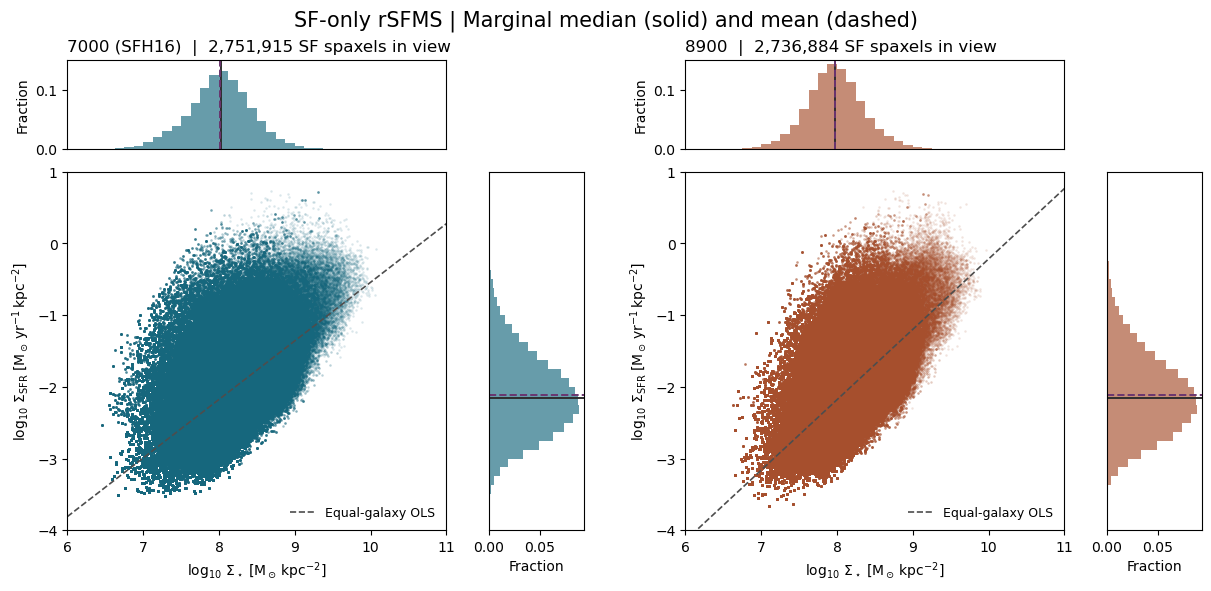

In [6]:
fig_scatter = plot_rsfms('scatter')

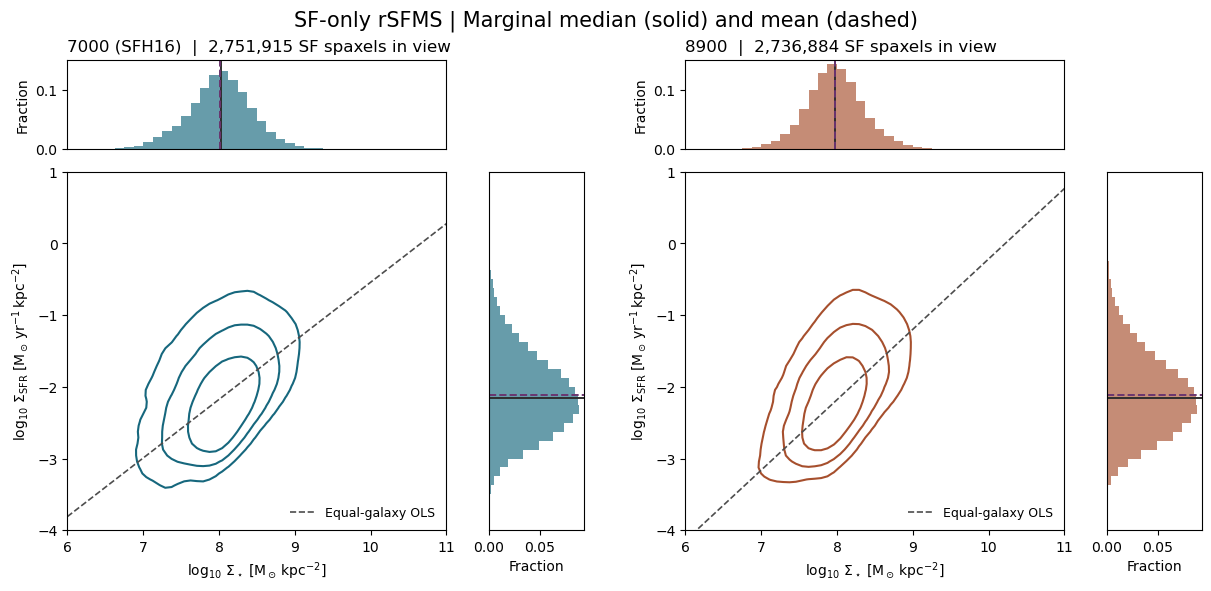

In [7]:
fig_contours = plot_rsfms('contours')

## Same-spaxel changes and galaxy influence

All differences are **7000 minus 8900** in dex. Same-spaxel diagnostics use
pixels selected as SF in both runs after checking shape and celestial WCS
across runs. A grid mismatch excludes that cube from the paired diagnostics.
The run-specific figures above retain its eligible pixels. The selection
counts report where independent SF masks differ, including changes in any
upstream quality cut.

Compare the signed offsets, median absolute changes, and the fraction of
pairs with `|Δmass| > |ΔSFR|`. The primary comparison averages galaxy medians,
so a large SF footprint does not set the result. The pooled calculation
answers the corresponding spaxel-weighted question. The leave-one-cube-out
table drops both NGC4567/8 components together.

In [8]:
pairing_inventory = pd.DataFrame(pairing_rows).set_index('product_id')
display(pairing_inventory)
pair_rows = []
for galaxy, p in paired.items():
    n_both = p['pixel'].size
    record = dict(galaxy=galaxy, product_id=p['product_id'], N_both=n_both,
                  N_only_8900=p['old_pixels'].size - n_both,
                  N_only_7000=p['new_pixels'].size - n_both)
    if n_both:
        dx = p['dx'] = p['x1'] - p['x0']
        dy = p['dy'] = p['y1'] - p['y0']
        ax, ay = np.abs(dx), np.abs(dy)
        record.update(median_dx=np.median(dx), median_dy=np.median(dy),
                      median_abs_dx=np.median(ax), median_abs_dy=np.median(ay),
                      median_abs_gap=np.median(ax - ay),
                      mass_moves_more_fraction=np.mean(ax > ay),
                      median_displacement=np.median(np.hypot(dx, dy)))
    pair_rows.append(record)

if not any(r['N_both'] for r in pair_rows):
    raise RuntimeError('No native-grid pixels selected as SF in both runs. See pairing inventory.')

galaxy_changes = pd.DataFrame(pair_rows).set_index('galaxy')
ranked_changes = galaxy_changes.sort_values('median_displacement', ascending=False)
display(ranked_changes.round(4))
usable_changes = ranked_changes.loc[ranked_changes.N_both.gt(0)]
active = [paired[name] for name in usable_changes.index]
abs_dx = np.abs(np.concatenate([p['dx'] for p in active]))
abs_dy = np.abs(np.concatenate([p['dy'] for p in active]))
metrics = ['median_abs_dx', 'median_abs_dy', 'median_abs_gap', 'mass_moves_more_fraction']
pooled = [np.median(abs_dx), np.median(abs_dy), np.median(abs_dx - abs_dy),
          np.mean(abs_dx > abs_dy)]
equal_galaxy = usable_changes[metrics].mean()
display(pd.DataFrame([pooled, equal_galaxy.to_numpy()], columns=metrics,
                     index=['Pooled spaxels', 'Mean of galaxy statistics']).round(4))

omit_rows = []
for product_id in usable_changes.product_id.unique():
    keep = usable_changes.loc[usable_changes.product_id.ne(product_id)]
    if not keep.empty:
        without = keep.median_abs_gap.mean()
        omit_rows.append(dict(omitted_cube=product_id, gap_without_cube=without,
                              change_from_full=without - equal_galaxy['median_abs_gap']))
if omit_rows:
    influence = pd.DataFrame(omit_rows).set_index('omitted_cube')
    display(influence.loc[influence.change_from_full.abs().sort_values(ascending=False).index].round(4))

,status
product_id,
IC3392,paired on native grid
NGC4064,paired on native grid
NGC4189,paired on native grid
NGC4254,paired on native grid
NGC4293,paired on native grid
NGC4294,paired on native grid
NGC4298,paired on native grid
NGC4321,paired on native grid
NGC4351,paired on native grid


,product_id,N_both,N_only_8900,N_only_7000,median_dx,median_dy,median_abs_dx,median_abs_dy,median_abs_gap,mass_moves_more_fraction,median_displacement
galaxy,,,,,,,,,,,
NGC4689,NGC4689,157155,21171,22791,0.2046,0.0060,0.2073,0.1101,0.0723,0.6567,0.2840
NGC4351,NGC4351,25504,4227,4263,-0.1585,0.0085,0.1900,0.1008,0.0610,0.6728,0.2676
NGC4579,NGC4579,94912,19021,16806,0.1770,0.0063,0.1800,0.1078,0.0528,0.6235,0.2539
NGC4321,NGC4321,320311,54993,62510,0.0979,0.0076,0.1521,0.0943,0.0441,0.6208,0.2247
NGC4548,NGC4548,76491,23069,27120,0.0757,0.0023,0.1002,0.1397,-0.0362,0.3949,0.2140
NGC4189,NGC4189,74194,6477,14388,-0.0071,0.0016,0.1251,0.1080,0.0064,0.5198,0.2137
NGC4294,NGC4294,59773,7739,6764,-0.0979,0.0000,0.1578,0.0729,0.0685,0.6853,0.2121
NGC4654,NGC4654,292890,27891,32788,0.0317,0.0073,0.1396,0.0830,0.0412,0.6219,0.2063
NGC4254,NGC4254,403018,63005,50562,-0.0374,0.0038,0.1464,0.0746,0.0575,0.6736,0.2024


,median_abs_dx,median_abs_dy,median_abs_gap,mass_moves_more_fraction
Pooled spaxels,0.1322,0.0849,0.0344,0.6084
Mean of galaxy statistics,0.1168,0.0777,0.0294,0.6087


,gap_without_cube,change_from_full
omitted_cube,,
NGC4698,0.0318,0.0024
NGC4380,0.0317,0.0023
NGC4548,0.0317,0.0023
NGC4383,0.0274,-0.0021
NGC4394,0.0315,0.0020
NGC4450,0.0312,0.0018
NGC4293,0.0312,0.0018
NGC4694,0.0279,-0.0016
NGC4064,0.0279,-0.0015


## Does the rSFMS actually broaden?

The scatter statistic is half the 84th–16th percentile interval of the
vertical log-SFR residuals, in dex. The table shows pooled scatter and the
mean of within-galaxy scatter values. Each row gets its own equal-galaxy OLS
fit. Compare the two run-specific rows with the two same-spaxel rows to
assess the role of changing SF selection. The two hybrid rows change just
one coordinate on the same SF spaxels, to show how mass and SFR shifts affect
slope and scatter. Hybrid effects need not add when the shifts covary.
Small galaxy samples and spatially correlated spaxels make these descriptive
comparisons.

In [9]:
def half_width(values):
    low, high = np.percentile(values, (16, 84))
    return (high - low) / 2


def relation_summary(samples):
    # Equal total weight per galaxy using centered sufficient statistics.
    samples = [(x - 8.0, y) for x, y in samples if x.size]
    mx = np.mean([x.mean() for x, y in samples])
    my = np.mean([y.mean() for x, y in samples])
    variance = np.mean([np.mean((x - mx)**2) for x, y in samples])
    if variance == 0:
        return dict(slope=np.nan, fitted_log_SFR_at_8=np.nan,
                    pooled_residual_width=np.nan, mean_galaxy_residual_width=np.nan)
    slope = np.mean([np.mean((x - mx) * (y - my)) for x, y in samples]) / variance
    intercept8 = my - slope * mx
    residuals = [y - (slope * x + intercept8) for x, y in samples]
    return dict(slope=slope, fitted_log_SFR_at_8=intercept8,
                pooled_residual_width=half_width(np.concatenate(residuals)),
                mean_galaxy_residual_width=np.mean([half_width(r) for r in residuals]))


relation_rows = {
    f'{run}: own SF selection': relation_summary(matched[run].values()) for run in (old_run, new_run)
}
for label, xkey, ykey in (
    ('8900: same SF pixels', 'x0', 'y0'),
    ('7000 mass + 8900 SFR: same SF pixels', 'x1', 'y0'),
    ('8900 mass + 7000 SFR: same SF pixels', 'x0', 'y1'),
    ('7000: same SF pixels', 'x1', 'y1'),
):
    relation_rows[label] = relation_summary([(p[xkey], p[ykey]) for p in active])
relation_comparison = pd.DataFrame.from_dict(relation_rows, orient='index')
display(relation_comparison.round(4))
reference_slope = relation_rows['8900: same SF pixels']['slope']

,slope,fitted_log_SFR_at_8,pooled_residual_width,mean_galaxy_residual_width
8900: own SF selection,0.9826,-2.1801,0.4651,0.3993
7000 (SFH16): own SF selection,0.8176,-2.1757,0.4942,0.4205
8900: same SF pixels,0.9686,-2.1440,0.4570,0.3994
7000 mass + 8900 SFR: same SF pixels,0.7985,-2.1418,0.4876,0.4228
8900 mass + 7000 SFR: same SF pixels,0.9660,-2.1382,0.4570,0.3982
7000: same SF pixels,0.8003,-2.1369,0.4876,0.4182


## Where do the changes occur?

The first figure bins the common SF sample by its **8900** mass and SFR
coordinates. Color shows the pooled median change in each 0.25-dex cell
with at least 50 spaxels. The last panel shows the change in vertical
residual relative to the fixed 8900 relation, `Δlog ΣSFR − slope₈₉₀₀ × Δlog Σ★`.
Binning on the older measurement can produce regression-to-the-mean patterns.

The sky maps show signed changes on the common SF footprint and identify
pixels selected in only one run. By default they show the three galaxies with
the largest median paired displacement in the mass–SFR plane. Set
`MAP_GALAXIES` to inspect specific galaxies. Colors for the two signed maps
share the same symmetric dex scale across both quantities and plotted galaxies.

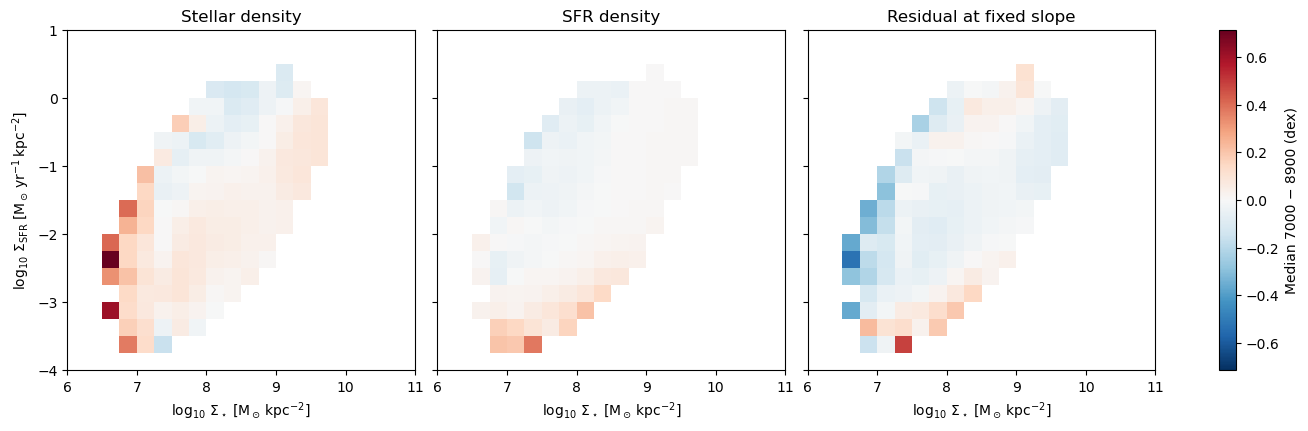

In [10]:
from scipy.stats import binned_statistic_2d

x0 = np.concatenate([p['x0'] for p in active])
y0 = np.concatenate([p['y0'] for p in active])
dx = np.concatenate([p['dx'] for p in active])
dy = np.concatenate([p['dy'] for p in active])
delta_residual = dy - reference_slope * dx
edges = (np.linspace(*X_LIMITS, 21), np.linspace(*Y_LIMITS, 21))
support, _, _ = np.histogram2d(x0, y0, bins=edges)
spaxel_fields = (
    ('Stellar density', dx), ('SFR density', dy), ('Residual at fixed slope', delta_residual)
)
shift_grids = []
for title, values in spaxel_fields:
    median = np.full(support.shape, np.nan)
    finite = np.isfinite(values)
    if finite.any():
        median = binned_statistic_2d(x0[finite], y0[finite], values[finite],
                                     statistic='median', bins=edges).statistic
        median[support < 50] = np.nan
    shift_grids.append(median)

fig_parameter, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True,
                                   layout='constrained')
finite_medians = np.concatenate([m[np.isfinite(m)] for m in shift_grids])
scale = max(np.max(np.abs(finite_medians), initial=0), 0.01)
for ax, (title, _), median in zip(axes, spaxel_fields, shift_grids):
    artist = ax.pcolormesh(*edges, median.T, cmap='RdBu_r', vmin=-scale, vmax=scale)
    ax.set(title=title, xlabel=X_LABEL)
axes[0].set_ylabel(Y_LABEL)
fig_parameter.colorbar(artist, ax=axes, label='Median 7000 − 8900 (dex)')
plt.show()

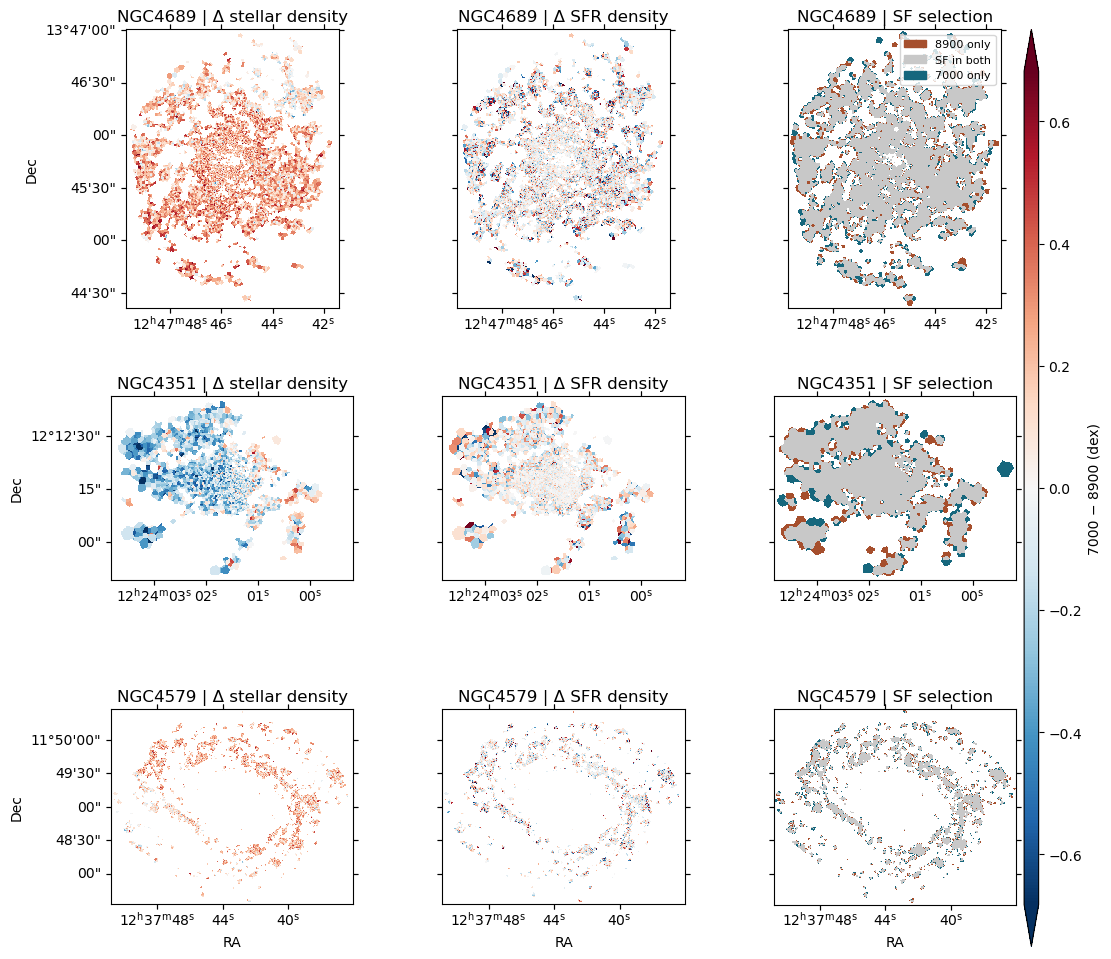

In [11]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

names = list(usable_changes.index[:3]) if MAP_GALAXIES is None else list(MAP_GALAXIES)
unknown = set(names) - set(usable_changes.index)
if not names or unknown:
    raise ValueError(f'MAP_GALAXIES must select galaxies with paired SF pixels. Unavailable: {unknown}')

scale = max(0.01, *(np.percentile(np.abs(paired[g][key]), 98)
                    for g in names for key in ('dx', 'dy')))
fig_sky = plt.figure(figsize=(11, 3.3 * len(names)), layout='constrained')
grid = fig_sky.add_gridspec(len(names), 4, width_ratios=(1, 1, 1, 0.06))
categorical_axes = []
categories = ('8900 only', 'SF in both', '7000 only')
category_colors = ('#a64f2d', '#c8c8c8', '#16677d')
for row, galaxy in enumerate(names):
    p = paired[galaxy]
    wcs = WCS(p['header']).celestial
    yy, xx = np.unravel_index(np.union1d(p['old_pixels'], p['new_pixels']), p['shape'])
    limits = (xx.min() - 5, xx.max() + 5, yy.min() - 5, yy.max() + 5)
    categories_map = np.full(p['shape'], np.nan, dtype=np.float32)
    categories_map.flat[p['old_pixels']] = 0
    categories_map.flat[p['new_pixels']] = 2
    categories_map.flat[p['pixel']] = 1
    for col, (key, label) in enumerate((('dx', 'Δ stellar density'), ('dy', 'Δ SFR density'),
                                        ('selection', 'SF selection'))):
        ax = fig_sky.add_subplot(grid[row, col], projection=wcs)
        if key == 'selection':
            ax.imshow(categories_map, origin='lower', interpolation='nearest',
                      cmap=ListedColormap(category_colors), vmin=-0.5, vmax=2.5)
            categorical_axes.append(ax)
        else:
            image = np.full(p['shape'], np.nan, dtype=np.float32)
            image.flat[p['pixel']] = p[key]
            artist = ax.imshow(image, origin='lower', cmap='RdBu_r', interpolation='nearest',
                               vmin=-scale, vmax=scale)
        ax.set(xlim=limits[:2], ylim=limits[2:], title=f'{galaxy} | {label}')
        ax.coords[0].set_axislabel('RA' if row == len(names) - 1 else '')
        ax.coords[1].set_axislabel('Dec' if col == 0 else '')
        ax.coords[0].set_ticklabel(exclude_overlapping=True)
        ax.coords[1].set_ticklabel(exclude_overlapping=True)
        ax.coords[1].set_ticklabel_visible(col == 0)
fig_sky.colorbar(artist, cax=fig_sky.add_subplot(grid[:, 3]), extend='both', label='7000 − 8900 (dex)')
categorical_axes[0].legend(handles=[Patch(color=c, label=l) for c, l in zip(category_colors, categories)],
                           fontsize=8, loc='best')
plt.show()